# 02 · Ecommerce funnel and significance tests

`view_item → add_to_cart → begin_checkout → add_shipping_info → add_payment_info → purchase`,
by device, channel and new vs returning users.

**Method**
- Unit: the session. *Closed* funnel = steps happened in order; *open* = the event happened at all.
- Pairwise: two-proportion z-test, Newcombe interval, Holm correction within each dimension.
- Omnibus: chi-square test of homogeneity across all segments of a dimension.
- Effect size: Cohen's h and relative lift, because with 139k sessions small gaps are "significant".
- Dependence: a user-clustered (Poisson) bootstrap, since one user can contribute several sessions.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ga4_analytics import funnel as F
from ga4_analytics.db import Warehouse
from ga4_analytics.plots import HIGHLIGHT, NEUTRAL, PALETTE, save, use_style

use_style()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
wh = Warehouse()
segments = F.funnel_segments(wh)
closed = F.funnel_long(segments, "closed")
opened = F.funnel_long(segments, "open")

-- 07_funnel.sql
dry run OK | local tables: ga4.main.sessions


## Overall funnel

In [2]:
overall = closed[closed["dimension"] == "all"][["step", "reached", "step_rate", "overall_rate"]]
overall_open = opened[opened["dimension"] == "all"][["step", "reached"]].rename(columns={"reached": "reached_open"})
overall = overall.merge(overall_open, on="step")
overall["lost_to_ordering_or_tracking"] = overall["reached_open"] - overall["reached"]
overall

,step,reached,step_rate,overall_rate,reached_open,lost_to_ordering_or_tracking
0,view_item,63252,0.4544,0.4544,63252,0
1,add_to_cart,20783,0.3286,0.1493,20783,0
2,begin_checkout,11927,0.5739,0.0857,12013,86
3,add_shipping_info,8826,0.7400,0.0634,8990,164
4,add_payment_info,6516,0.7383,0.0468,6761,245
5,purchase,3874,0.5945,0.0278,4218,344


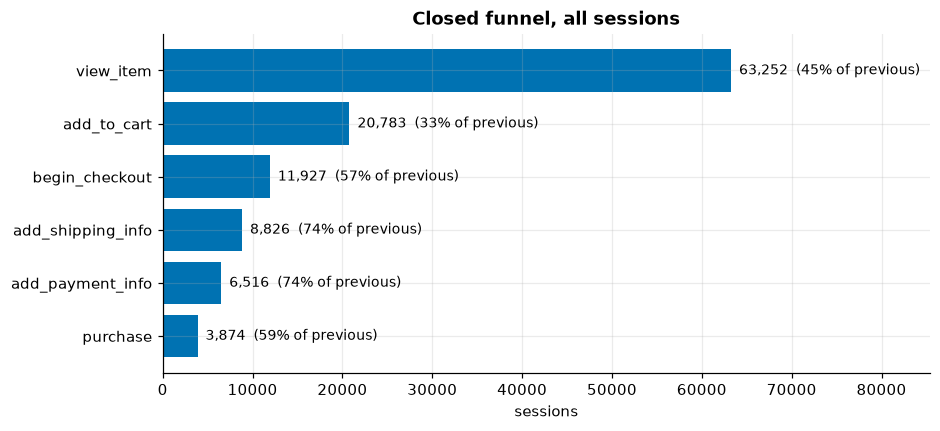

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(overall["step"][::-1], overall["reached"][::-1], color=PALETTE[0])
for y, (n, r) in enumerate(zip(overall["reached"][::-1], overall["step_rate"][::-1], strict=True)):
    ax.text(n, y, f"  {n:,}  ({r:.0%} of previous)", va="center", fontsize=9)
ax.set_title("Closed funnel, all sessions")
ax.set_xlabel("sessions")
ax.set_xlim(0, overall["reached"].max() * 1.35)
save(fig, "02_funnel_overall")

The open funnel counts more purchases than the closed one: some purchasing sessions are missing
an earlier checkout event. That is a tracking gap (an injected defect), not customer behaviour, so
the closed funnel is used for step rates and both are reported.

## By device

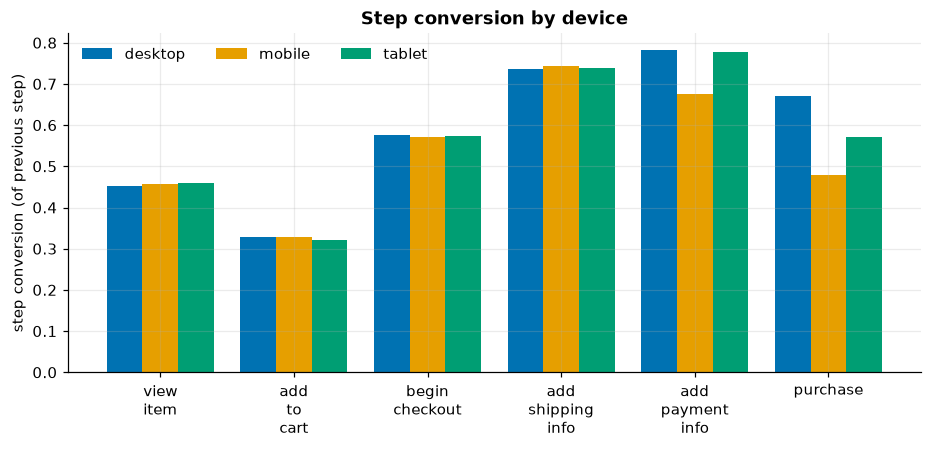

In [4]:
def plot_step_rates(dim: str, title: str, name: str) -> None:
    d = closed[closed["dimension"] == dim]
    order = d.groupby("segment")["sessions"].max().sort_values(ascending=False).index
    fig, ax = plt.subplots(figsize=(10, 4))
    width = 0.8 / len(order)
    x = np.arange(len(F.STEPS))
    for i, seg in enumerate(order):
        s = d[d["segment"] == seg].set_index("step").loc[F.STEPS]
        ax.bar(x + i * width, s["step_rate"], width, label=seg, color=PALETTE[i % len(PALETTE)])
    ax.set_xticks(x + width * (len(order) - 1) / 2, [s.replace("_", "\n") for s in F.STEPS])
    ax.set_ylabel("step conversion (of previous step)")
    ax.set_title(title)
    ax.legend(ncols=min(len(order), 4))
    save(fig, name)


plot_step_rates("device", "Step conversion by device", "02_steps_by_device")

In [5]:
F.compare_segments(closed, "device")

,segment,reference,rate,reference_rate,diff,ci_low,ci_high,relative_lift,z,p_value,cohens_h,n,p_holm,significant
0,mobile,desktop,0.0206,0.0331,-0.0125,-0.0142,-0.0108,-0.3773,-13.7925,0.0000,-0.0778,57158,0.0000,True
1,tablet,desktop,0.0278,0.0331,-0.0053,-0.0100,0.0003,-0.1594,-1.8706,0.0614,-0.0307,4202,0.0614,False


In [6]:
dev = closed[(closed["dimension"] == "device") & (closed["step"] == "purchase")]
stat, p, dof = F.chi_square(dev["reached"].tolist(), dev["sessions"].tolist())
print(f"chi-square across devices: X2 = {stat:.1f}, dof = {dof}, p = {p:.2e}")

chi-square across devices: X2 = 190.2, dof = 2, p = 4.92e-42


### Where does mobile lose conversion?

Test each step's rate (of the previous step) for mobile against desktop.

In [7]:
mobile_steps = F.step_tests(closed, "device", "mobile", "desktop")
mobile_steps

,step,mobile_rate,desktop_rate,diff,ci_low,ci_high,relative_lift,p_value,p_holm,significant
0,view_item,0.4569,0.4523,0.0045,-0.0009,0.0099,0.0100,0.0994,0.3975,False
1,add_to_cart,0.3283,0.3291,-0.0008,-0.0083,0.0067,-0.0024,0.8355,1.0000,False
2,begin_checkout,0.5720,0.5753,-0.0033,-0.0172,0.0105,-0.0058,0.6356,1.0000,False
3,add_shipping_info,0.7441,0.7370,0.0071,-0.0091,0.0232,0.0096,0.3921,1.0000,False
4,add_payment_info,0.6750,0.7832,-0.1082,-0.1273,-0.0892,-0.1382,0.0000,0.0000,True
5,purchase,0.4787,0.6700,-0.1913,-0.2158,-0.1665,-0.2855,0.0000,0.0000,True


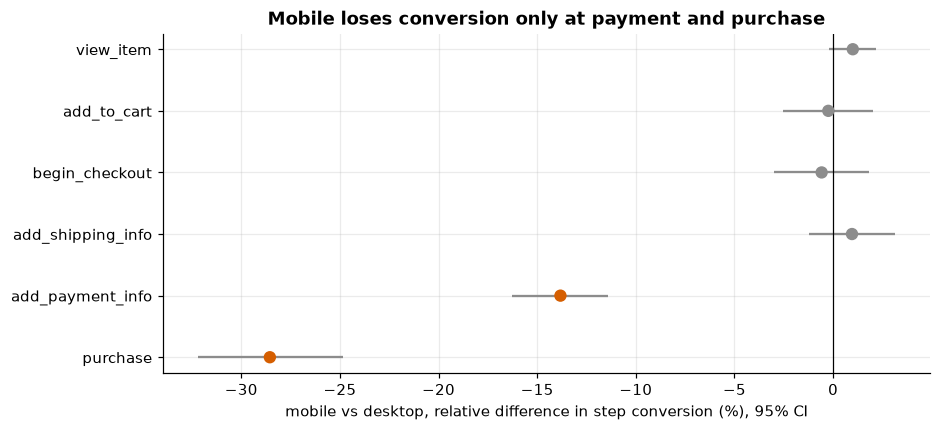

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = [HIGHLIGHT if s else NEUTRAL for s in mobile_steps["significant"]]
ax.errorbar(mobile_steps["relative_lift"] * 100, np.arange(len(F.STEPS)), fmt="none", ecolor=NEUTRAL,
            xerr=[(mobile_steps["diff"] - mobile_steps["ci_low"]) / mobile_steps["desktop_rate"] * 100,
                  (mobile_steps["ci_high"] - mobile_steps["diff"]) / mobile_steps["desktop_rate"] * 100])
ax.scatter(mobile_steps["relative_lift"] * 100, np.arange(len(F.STEPS)), color=colors, zorder=3, s=50)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(np.arange(len(F.STEPS)), F.STEPS)
ax.invert_yaxis()
ax.set_xlabel("mobile vs desktop, relative difference in step conversion (%), 95% CI")
ax.set_title("Mobile loses conversion only at payment and purchase")
save(fig, "02_mobile_step_gap")

The gap sits entirely in the last two steps: about −14% at `add_payment_info` and −29% at
`purchase`, with nothing significant upstream. Mobile users browse and add to cart like desktop
users, then fail at payment. **That points to the mobile payment form, not to traffic quality.**

*Ground truth check:* the generator planted ×0.85 at payment and ×0.72 at purchase on mobile
(−15% and −28%). The test recovers both and correctly finds nothing at the other four steps.

## By channel

,segment,reference,rate,reference_rate,diff,ci_low,ci_high,relative_lift,z,p_value,cohens_h,n,p_holm,significant
0,Display,Organic Search,0.0116,0.0255,-0.0140,-0.0164,-0.0114,-0.5473,-8.9985,0.0000,-0.1055,11861,0.0000,True
1,Organic Social,Organic Search,0.0131,0.0255,-0.0124,-0.0149,-0.0098,-0.4862,-8.1092,0.0000,-0.0913,12509,0.0000,True
2,Referral,Organic Search,0.0201,0.0255,-0.0054,-0.0083,-0.0022,-0.2107,-3.2938,0.0010,-0.0361,11669,0.0030,True
3,Affiliates,Organic Search,0.0243,0.0255,-0.0012,-0.0055,0.0037,-0.0468,-0.5008,0.6165,-0.0077,4934,0.6165,False
4,Paid Search,Organic Search,0.0295,0.0255,0.0040,0.0012,0.0069,0.1575,2.8232,0.0048,0.0246,19842,0.0095,True
5,Direct,Organic Search,0.0363,0.0255,0.0108,0.0082,0.0135,0.4246,8.0693,0.0000,0.0628,29053,0.0000,True
6,Email,Organic Search,0.0515,0.0255,0.0259,0.0218,0.0303,1.0170,14.1531,0.0000,0.1369,12242,0.0000,True


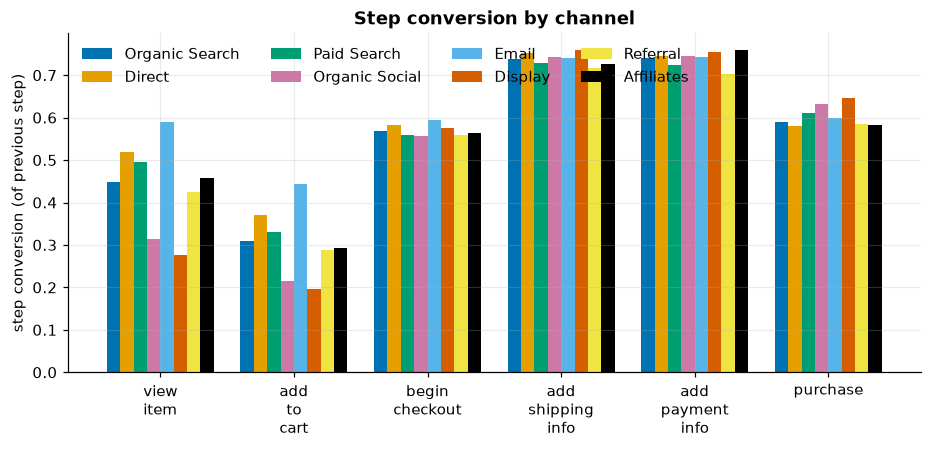

In [9]:
plot_step_rates("channel", "Step conversion by channel", "02_steps_by_channel")
F.compare_segments(closed, "channel")

In [10]:
ch = closed[(closed["dimension"] == "channel") & (closed["step"] == "purchase")]
stat, p, dof = F.chi_square(ch["reached"].tolist(), ch["sessions"].tolist())
print(f"chi-square across channels: X2 = {stat:.1f}, dof = {dof}, p = {p:.2e}")
F.compare_segments(closed, "channel", step="add_to_cart", rate="step")

chi-square across channels: X2 = 584.1, dof = 7, p = 6.36e-122


,segment,reference,rate,reference_rate,diff,ci_low,ci_high,relative_lift,z,p_value,cohens_h,n,p_holm,significant
0,Display,Organic Search,0.1963,0.3096,-0.1132,-0.1283,-0.0976,-0.3658,-13.0330,0.0000,-0.2620,3270,0.0000,True
1,Organic Social,Organic Search,0.2140,0.3096,-0.0955,-0.1099,-0.0807,-0.3086,-11.8603,0.0000,-0.2181,3934,0.0000,True
2,Referral,Organic Search,0.2873,0.3096,-0.0222,-0.0365,-0.0077,-0.0718,-2.9899,0.0028,-0.0486,4970,0.0056,True
3,Affiliates,Organic Search,0.2930,0.3096,-0.0166,-0.0363,0.0037,-0.0536,-1.6045,0.1086,-0.0362,2263,0.1086,False
4,Paid Search,Organic Search,0.3303,0.3096,0.0208,0.0091,0.0324,0.0671,3.5086,0.0005,0.0445,9851,0.0014,True
5,Direct,Organic Search,0.3703,0.3096,0.0607,0.0503,0.0711,0.1961,11.4164,0.0000,0.1283,15094,0.0000,True
6,Email,Organic Search,0.4446,0.3096,0.1351,0.1216,0.1485,0.4363,20.0930,0.0000,0.2798,7224,0.0000,True


Channel differences are concentrated at the top of the funnel (product views and add to cart):
Email and Direct sessions engage far more than Display and Organic Social. Once a session reaches
checkout, channels convert alike. Channel is a traffic-quality question; device is a checkout
question.

Session-level channel conversion is **not** channel value: Display and Social sessions convert
poorly but start journeys that convert later. Notebook 03 handles that with attribution.

## New vs returning

,segment,reference,rate,reference_rate,diff,ci_low,ci_high,relative_lift,z,p_value,cohens_h,n,p_holm,significant
0,returning,new,0.0364,0.0215,0.0149,0.0131,0.0167,0.6940,16.7235,0.0000,0.0897,59196,0.0000,True


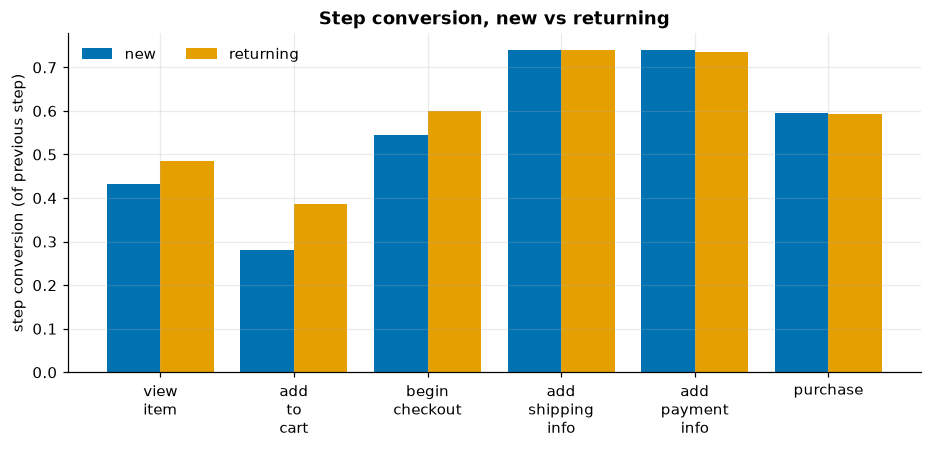

In [11]:
plot_step_rates("user_type", "Step conversion, new vs returning", "02_steps_by_user_type")
F.compare_segments(closed, "user_type", reference="new")

In [12]:
F.step_tests(closed, "user_type", "returning", "new")

,step,returning_rate,new_rate,diff,ci_low,ci_high,relative_lift,p_value,p_holm,significant
0,view_item,0.4854,0.4315,0.0539,0.0486,0.0591,0.1248,0.0000,0.0000,True
1,add_to_cart,0.3866,0.2803,0.1064,0.0990,0.1137,0.3796,0.0000,0.0000,True
2,begin_checkout,0.5999,0.5440,0.0558,0.0424,0.0693,0.1026,0.0000,0.0000,True
3,add_shipping_info,0.7404,0.7395,0.0009,-0.0149,0.0168,0.0012,0.9120,1.0000,False
4,add_payment_info,0.7363,0.7408,-0.0044,-0.0228,0.0141,-0.0060,0.6382,1.0000,False
5,purchase,0.5932,0.5963,-0.0031,-0.0270,0.0209,-0.0052,0.8014,1.0000,False


## Do repeat sessions break the z-test?

The z-test assumes independent sessions. A user-clustered bootstrap resamples users instead.

In [13]:
s = wh.query("SELECT user_pseudo_id, user_type, device_category, reached_purchase::INT AS reached_purchase "
             "FROM sessions", dry_run=False)
boot = pd.DataFrame({
    "returning vs new": F.cluster_bootstrap_diff(s, "user_type", "returning", "new"),
    "mobile vs desktop": F.cluster_bootstrap_diff(s, "device_category", "mobile", "desktop"),
}).T
boot

,diff,ci_low,ci_high,boot_se,naive_se,design_effect,users
returning vs new,0.0165,0.0146,0.0184,0.0010,0.0010,0.9820,"80,000.0000"
mobile vs desktop,-0.0136,-0.0154,-0.0117,0.0009,0.0009,1.0252,"77,617.0000"


The design effect is about 1: in this data a user's sessions convert independently, so clustering
barely widens the intervals. On real data users differ in purchase intent, the design effect is
usually above 1, and the naive z-test overstates significance; the bootstrap is the safer default.

## What could we detect at all?

In [14]:
base = closed[(closed["dimension"] == "all") & (closed["step"] == "purchase")]["overall_rate"].iloc[0]
mde = pd.DataFrame([
    {"comparison": name, "n1": n1, "n2": n2,
     "mde_abs_pp": 100 * F.minimum_detectable_effect(base, n1, n2),
     "mde_relative": F.minimum_detectable_effect(base, n1, n2) / base}
    for name, n1, n2 in [
        ("mobile vs desktop", int(segments.query("segment == 'mobile'")["sessions"].iloc[0]),
         int(segments.query("segment == 'desktop'")["sessions"].iloc[0])),
        ("tablet vs desktop", int(segments.query("segment == 'tablet'")["sessions"].iloc[0]),
         int(segments.query("segment == 'desktop'")["sessions"].iloc[0])),
        ("Affiliates vs Organic Search", int(segments.query("segment == 'Affiliates'")["sessions"].iloc[0]),
         int(segments.query("segment == 'Organic Search'")["sessions"].iloc[0])),
    ]
])
mde

,comparison,n1,n2,mde_abs_pp,mde_relative
0,mobile vs desktop,57158,77827,0.2539,0.0912
1,tablet vs desktop,4202,77827,0.7299,0.2622
2,Affiliates vs Organic Search,4934,37077,0.6984,0.2509


Tablet (about 4k sessions) can only detect a gap of roughly a quarter of the baseline, so "tablet is
not significantly different" means "too small to tell", not "the same".

## Conclusions

1. **Mobile checkout is the biggest fixable leak.** Mobile converts about 38% worse than desktop,
   and all of it is lost at payment and purchase (Holm-adjusted p < 1e-10 at both).
2. **Channel differences are traffic quality,** located at product views and add to cart, not
   at checkout.
3. **Returning sessions convert better** at the first three steps (product views +12%, add to cart
   +38%, checkout starts +10%). Once in checkout, new and returning complete at the same rate. Part
   of the top-of-funnel gap is channel mix: return visits come more from Email and Direct.
4. **Tablet is underpowered;** no conclusion either way.